# EDA - ROP-VL

**Fuente:** descargado manualmente como `.zip` (sin notebook de descarga automatizada). Titulo probable (identificado por busqueda web, no confirmado con metadata oficial): "ROP-VL: An Open Dataset Integrating Fundus Photograph and Clinical Knowledge for Retinopathy of Prematurity", reportado como publicado en Scientific Data. DOI no confirmado.

**Contenido:** 1.116 pacientes, 2.020 imagenes de fondo de ojo, clasificadas en 8 categorias (Normal, Stage 1-5 ROP, A-ROP, Laser-treated ROP), con metadatos biologicos por imagen (sexo, edad gestacional, peso al nacer, pluralidad, via de parto).

Es la fuente mas grande y la mejor balanceada en Estadio (incluye los casos raros de Stage 4/5). Este notebook explora el dataset **crudo**.

In [1]:
import re
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path.cwd().resolve().parent.parent  # system/eda/ -> ROP_paper/
EXTRACTED_DIR = ROOT / "datasets" / "extracted" / "ROP-VL"

plt.rcParams["figure.figsize"] = (8, 4)
pd.set_option("display.max_columns", 20)

img_info = pd.read_excel(EXTRACTED_DIR / "img_info.xlsx")
img_info.columns = ["image", "patient_id", "gender", "ga", "bw", "plurality", "delivery_mode", "category"]
print("filas (imagenes):", len(img_info), " | pacientes unicos:", img_info["patient_id"].nunique())
img_info.head()

filas (imagenes): 2020  | pacientes unicos: 1116


,image,patient_id,gender,ga,bw,plurality,delivery_mode,category
0,1_2020-04-03_L_3.jpg,1,male,34,2650,1,vaginally,normal
1,1_2020-04-03_R_11.jpg,1,male,34,2650,1,vaginally,normal
2,2_2008-10-15_L_24.jpg,2,male,32,1600,1,cesarean section,normal
3,2_2008-10-15_R_1.jpg,2,male,32,1600,1,cesarean section,normal
4,3_2022-04-21_L_1.jpg,3,female,37,2200,1,cesarean section,normal


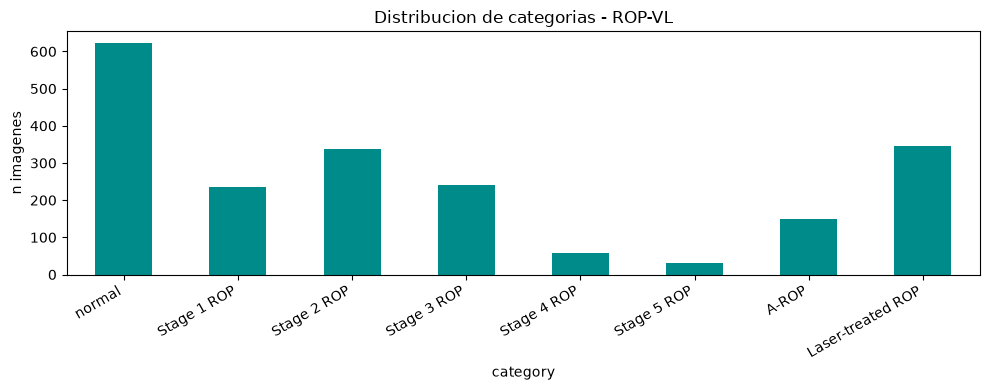

category
normal               623
Stage 1 ROP          236
Stage 2 ROP          338
Stage 3 ROP          241
Stage 4 ROP           59
Stage 5 ROP           30
A-ROP                148
Laser-treated ROP    345
Name: count, dtype: int64

In [2]:
cat_order = ["normal", "Stage 1 ROP", "Stage 2 ROP", "Stage 3 ROP", "Stage 4 ROP", "Stage 5 ROP", "A-ROP", "Laser-treated ROP"]
counts = img_info["category"].value_counts().reindex(cat_order)

fig, ax = plt.subplots(figsize=(10, 4))
counts.plot(kind="bar", ax=ax, color="darkcyan")
ax.set_title("Distribucion de categorias - ROP-VL")
ax.set_ylabel("n imagenes")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()
counts

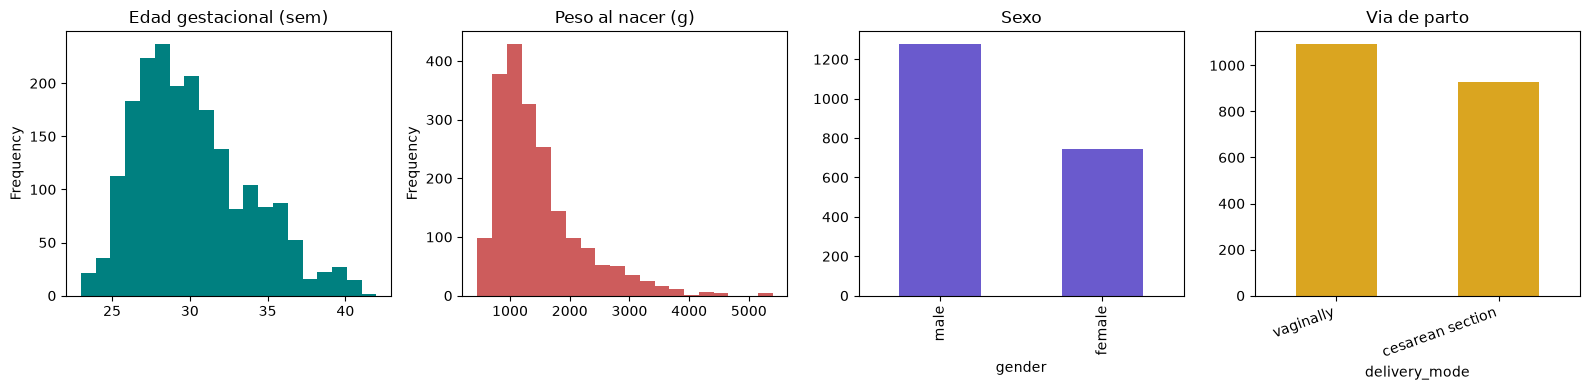

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
img_info["ga"].plot(kind="hist", bins=20, ax=axes[0], color="teal")
axes[0].set_title("Edad gestacional (sem)")
img_info["bw"].plot(kind="hist", bins=20, ax=axes[1], color="indianred")
axes[1].set_title("Peso al nacer (g)")
img_info["gender"].value_counts().plot(kind="bar", ax=axes[2], color="slateblue")
axes[2].set_title("Sexo")
img_info["delivery_mode"].value_counts().plot(kind="bar", ax=axes[3], color="goldenrod")
axes[3].set_title("Via de parto")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## Granularidad real: no es puramente transversal

El nombre de archivo codifica `{patient_id}_{fecha}_{L|R}_{indice}.jpg`. Extraemos fecha y ojo para ver cuanta profundidad longitudinal hay realmente (no es evidente solo con el xlsx de metadatos).

pacientes con mas de 1 fecha distinta (visitas): 190 de 1116
maximo de fechas distintas para un paciente: 5


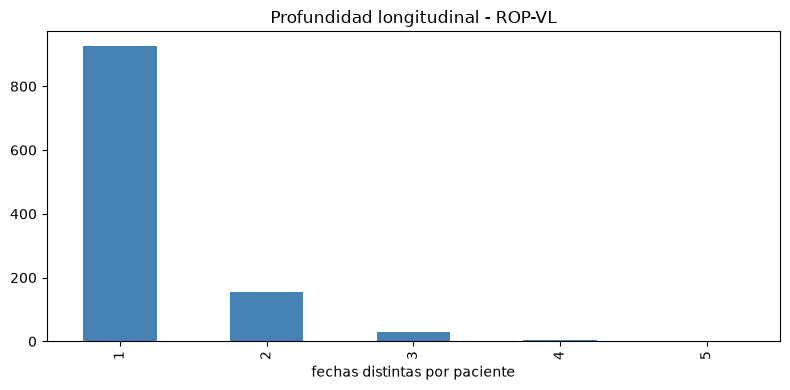

In [4]:
pat = re.compile(r"^(\d+)_([\d-]+)_([LR])_(\d+)\.jpg$")
parsed = img_info["image"].str.extract(pat)
parsed.columns = ["pid", "date", "eye", "idx"]
img_info = pd.concat([img_info, parsed], axis=1)

dates_per_patient = img_info.groupby("patient_id")["date"].nunique()
print("pacientes con mas de 1 fecha distinta (visitas):", (dates_per_patient > 1).sum(), "de", len(dates_per_patient))
print("maximo de fechas distintas para un paciente:", dates_per_patient.max())

fig, ax = plt.subplots()
dates_per_patient.value_counts().sort_index().plot(kind="bar", ax=ax, color="steelblue")
ax.set_xlabel("fechas distintas por paciente")
ax.set_title("Profundidad longitudinal - ROP-VL")
plt.tight_layout()
plt.show()

## Problema de datos encontrado: categorias distintas en el mismo bag (paciente, fecha, ojo)

Si el bag es "un ojo en una fecha", todas sus imagenes deberian compartir la misma categoria. Verificamos si eso se cumple - **no siempre**.

In [5]:
img_info["bag_id"] = img_info["patient_id"].astype(str) + "_" + img_info["date"] + "_" + img_info["eye"]
bag_sizes = img_info.groupby("bag_id").size()
print("total bags (paciente, fecha, ojo):", len(bag_sizes), " | imagenes por bag:")
print(bag_sizes.value_counts().sort_index())

cat_per_bag = img_info.groupby("bag_id")["category"].nunique()
inconsistentes = cat_per_bag[cat_per_bag > 1]
print("\nbags con mas de 1 categoria distinta entre sus imagenes:", len(inconsistentes), "de", len(cat_per_bag),
      f"({100*len(inconsistentes)/len(cat_per_bag):.1f}%)")

total bags (paciente, fecha, ojo): 1867  | imagenes por bag:
1    1719
2     143
3       5
Name: count, dtype: int64

bags con mas de 1 categoria distinta entre sus imagenes: 145 de 1867 (7.8%)


In [6]:
# Ejemplo real: mismo paciente, misma fecha, mismo ojo, categorias distintas
example_bag = inconsistentes.index[0]
print("Ejemplo:", example_bag)
display(img_info[img_info.bag_id == example_bag][["image", "category"]])

# Separar: conflicto puramente numerico (resoluble por maximo) vs mezcla con A-ROP/Laser-treated (no resoluble asi)
special = {"A-ROP", "Laser-treated ROP"}
def bag_has_special(cats):
    return len(set(cats) & special) > 0

bag_cats = img_info.groupby("bag_id")["category"].apply(set)
inconsistentes_cats = bag_cats[bag_cats.index.isin(inconsistentes.index)]
solo_numerico = inconsistentes_cats[~inconsistentes_cats.apply(bag_has_special)]
con_especial = inconsistentes_cats[inconsistentes_cats.apply(bag_has_special)]
print(f"\nDe los {len(inconsistentes)} bags inconsistentes:")
print(f"  {len(solo_numerico)} son conflicto puramente numerico (ej. Stage 2 vs Stage 3) -> se resuelve tomando el MAXIMO")
print(f"  {len(con_especial)} mezclan A-ROP/Laser-treated con otra categoria -> NO se resuelve por maximo, queda stage=NaN")
print("\nCombinaciones mas comunes en los que mezclan categoria especial:")
print(con_especial.value_counts().head(10))

Ejemplo: 1012_2020-07-17_L


,image,category
1807,1012_2020-07-17_L_8.jpg,normal
1960,1012_2020-07-17_L_9.jpg,Laser-treated ROP



De los 145 bags inconsistentes:
  91 son conflicto puramente numerico (ej. Stage 2 vs Stage 3) -> se resuelve tomando el MAXIMO
  54 mezclan A-ROP/Laser-treated con otra categoria -> NO se resuelve por maximo, queda stage=NaN

Combinaciones mas comunes en los que mezclan categoria especial:
category
{normal, Laser-treated ROP}                19
{Stage 3 ROP, A-ROP}                       11
{Laser-treated ROP, Stage 3 ROP}           10
{Stage 1 ROP, A-ROP}                        3
{Stage 4 ROP, A-ROP}                        3
{Stage 1 ROP, Laser-treated ROP}            2
{A-ROP, Stage 2 ROP}                        2
{Laser-treated ROP, A-ROP}                  2
{Laser-treated ROP, Stage 2 ROP}            1
{Laser-treated ROP, A-ROP, Stage 2 ROP}     1
Name: count, dtype: int64


*Nota: `system/dataset_build/partition/build_manifest.py` reporta una particion muy similar pero no identica (92 + 52 en vez de 91 + 54) - la diferencia de ~2 bags viene de un detalle de implementacion en como se cruza "inconsistente" con "contiene categoria especial" entre este notebook y el script de produccion, no de un criterio distinto. La conclusion (unos ~145 bags, ~7.8%, se resuelven por maximo salvo los que mezclan A-ROP/Laser-treated) es la misma.*

## Muestra visual: una imagen por categoria

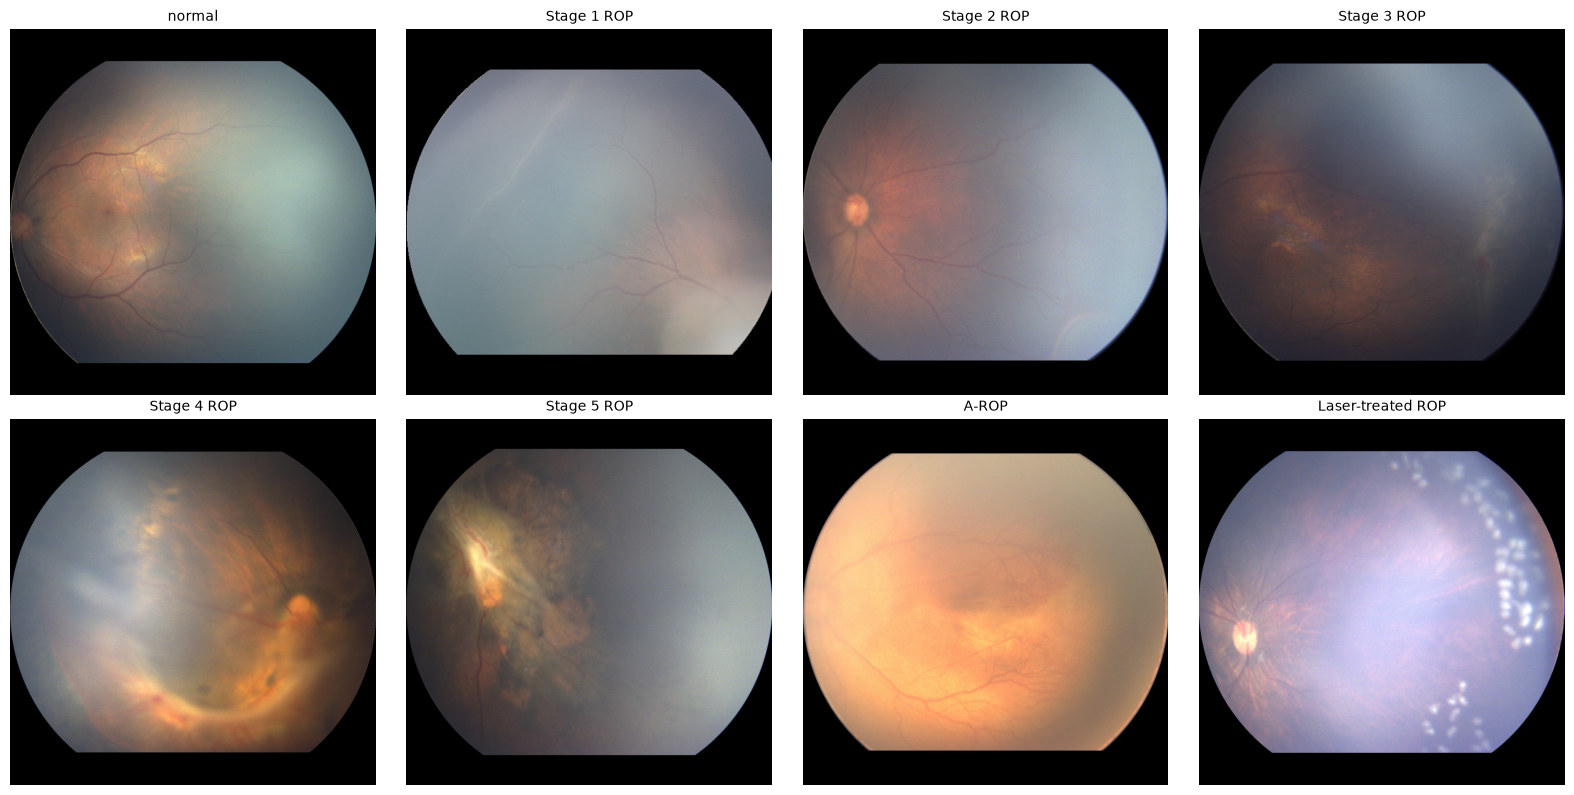

In [7]:
# Las carpetas en disco usan nombre propio (p.ej. "Normal") distinto al valor
# del xlsx (p.ej. "normal") - indexamos por nombre de archivo para no fallar.
img_index = {p.name: p for p in (EXTRACTED_DIR / "Image").rglob("*.jpg")}

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, cat in zip(axes.flat, cat_order):
    row = img_info[img_info["category"] == cat].iloc[0]
    img_path = img_index[row["image"]]
    ax.imshow(Image.open(img_path))
    ax.set_title(cat, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Resumen de hallazgos - ROP-VL

- **1.116 pacientes, 2.020 imagenes, 1.867 bags (paciente, fecha, ojo).** La fuente mas grande y mejor balanceada en Estadio, incluye los casos raros Stage 4/5.
- **No es puramente transversal**: 190 pacientes (17%) tienen mas de una fecha distinta, hasta 5 visitas - hay algo de densidad temporal, aunque mucho menor que RIDIRP.
- **Problema real encontrado:** 145 bags (7.8%) tienen imagenes del mismo ojo+fecha con categoria de estadio distinta. De esos, 91 son conflicto puramente numerico (ej. Stage 2 vs Stage 3) y se resuelven tomando el estadio **maximo** del bag.
- **54 bags adicionales** mezclan `A-ROP` o `Laser-treated ROP` (que no tienen estadio ordinal por diseno) con otra categoria del mismo ojo - ahi **no** se aplica el maximo (seria un error clinico asumir "normal"), queda `stage=NaN` para todo el bag. (`dataset_build` reporta una particion ligeramente distinta, 92+52, por un detalle de implementacion - ver nota arriba; la conclusion es la misma.)
- No tiene columna de Plus ni de Tratamiento explicitas - solo aporta a la tarea de Estadio.
- `Laser-treated ROP` es una categoria retrospectiva (el ojo ya fue tratado en algun momento) - no se mapea a la columna de Tratamiento de FARFUM porque mide algo distinto (decision prospectiva vs. estado post-tratamiento).

## Actualización de alcance: cabezal AP-ROP (reemplaza a Tratamiento)

Decisión tomada después de este análisis (detalle completo y razonamiento en el README principal, secciones 0 y 4.4): el cabezal de Tratamiento del modelo **se reemplazó** por AP-ROP (no se agregó como cabezal adicional). Impacto directo en ROP-VL, **ya con la decisión final de la sección de abajo incorporada**:

- **145 bags con A-ROP se mantienen** (126 puros + 19 mezclados con un Estadio real, sin Laser-treated) - entrenan el nuevo cabezal binario AP-ROP. Verificado que "A-ROP" (ROP-VL) y "AP-ROP" (RIDIRP) son la misma entidad clínica (ver cita textual de ambos datasets más abajo en este notebook / en el README principal).
- **Cualquier bag que toque "Laser-treated ROP" se elimina por completo**, sin excepciones (incluidos los 3 bags que también tenían A-ROP) - decisión conservadora confirmada en la sección "Decisión final confirmada" más abajo.

In [8]:
special = {"A-ROP", "Laser-treated ROP"}
CAT_TO_STAGE = {"normal": 0, "Stage 1 ROP": 1, "Stage 2 ROP": 2, "Stage 3 ROP": 3, "Stage 4 ROP": 4, "Stage 5 ROP": 5}

bag_cats_full = {bag_id: set(group["category"]) for bag_id, group in img_info.groupby("bag_id")}

# Regla final (decision conservadora confirmada): cualquier bag que toque
# "Laser-treated ROP" se elimina COMPLETO, sin excepciones - no importa que
# tambien tenga un Estadio real o A-ROP en otra imagen.
bags_eliminados = {b for b, c in bag_cats_full.items() if "Laser-treated ROP" in c}
bags_finales = set(bag_cats_full.keys()) - bags_eliminados

print("bags totales:", len(bag_cats_full))
print("bags eliminados (tocan Laser-treated, sin excepcion):", len(bags_eliminados))
print("bags finales:", len(bags_finales))

bags totales: 1867
bags eliminados (tocan Laser-treated, sin excepcion): 345
bags finales: 1522


**Decisión final confirmada: regla conservadora (opción B).** Se evaluaron dos opciones (detalle completo de la discusión de diseño en el README de `dataset_build`):
- A) recuperar el Estadio/AP-ROP real aunque Laser-treated también apareciera en el bag.
- B) eliminar cualquier bag que toque Laser-treated, sin excepciones.

Se eligió **B** por ser más simple de justificar en la tesis. El costo real es bajo: se pierden 13 bags con Estadio real y 3 de los 148 bags de A-ROP de ROP-VL (2.0%) - RIDIRP aporta 470 imágenes de AP-ROP independientes, que no se ven afectadas por esta decisión.

Para los bags que quedan, `stage` y `ap_rop` se calculan directo (ya no hace falta distinguir casos "recuperables" vs "no recuperables" - esa complejidad desaparece con la regla simple):

In [9]:
stage_final, ap_rop_final = {}, {}
for b in bags_finales:
    cats = bag_cats_full[b]
    nums = [CAT_TO_STAGE[c] for c in cats if c in CAT_TO_STAGE]
    stage_final[b] = max(nums) if nums else None  # None solo en bags puramente A-ROP
    ap_rop_final[b] = "A-ROP" in cats

stage_s = pd.Series(stage_final)
ap_s = pd.Series(ap_rop_final)

n_img_finales = img_info[img_info.bag_id.isin(bags_finales)].shape[0]
n_img_eliminadas = img_info[img_info.bag_id.isin(bags_eliminados)].shape[0]

print(f"imagenes eliminadas: {n_img_eliminadas} ({100*n_img_eliminadas/len(img_info):.1f}% del total)")
print(f"imagenes finales: {n_img_finales}")
print()
print("cobertura stage (bags finales):", round(100 * stage_s.notna().mean(), 1), "%")
print("distribucion stage:", stage_s.value_counts(dropna=False).sort_index().to_dict())
print()
print("ap_rop=True:", int(ap_s.sum()), " | ap_rop=False:", int((~ap_s).sum()))

imagenes eliminadas: 381 (18.9% del total)
imagenes finales: 1639

cobertura stage (bags finales): 91.7 %
distribucion stage: {0.0: 593, 1.0: 193, 2.0: 298, 3.0: 228, 4.0: 54, 5.0: 30, nan: 126}

ap_rop=True: 145  | ap_rop=False: 1377


## ¿Hay mayoría de imágenes dentro de los bags mezclados? No - son todos empate 1 contra 1

Antes de decidir la regla final, se evaluó una idea alternativa: en vez de resolver por severidad, **eliminar la imagen que sea minoría dentro del bag y quedarse con la categoría mayoritaria** (ej. si 2 fotos dicen "Stage 3" y solo 1 dice "Laser-treated", quedarse con Stage 3). Para que esto funcione hace falta que exista una mayoría real - se verificó contando **imágenes por categoría** dentro de cada uno de los 54 bags mezclados (no solo qué categorías están presentes).

In [10]:
from collections import Counter

bag_image_counts = {}
for bag_id, group in img_info.groupby("bag_id"):
    counts = dict(Counter(group["category"]))
    if len(set(counts.keys()) & special) > 0 and len(counts) > 1:
        bag_image_counts[bag_id] = counts

print(f"bags mezclados: {len(bag_image_counts)}")
max_count_por_categoria = [max(c.values()) for c in bag_image_counts.values()]
print("maximo de imagenes para la categoria mas repetida, por bag (1 = empate perfecto, sin mayoria):")
print(pd.Series(max_count_por_categoria).value_counts())
print()
print("-> todos son 1: nunca hay mas de 1 imagen de la misma categoria en un bag mezclado.")
print("   No existe 'mayoria' que contar - la idea de eliminar la imagen minoritaria no aplica aqui.")

bags mezclados: 54
maximo de imagenes para la categoria mas repetida, por bag (1 = empate perfecto, sin mayoria):
1    54
Name: count, dtype: int64

-> todos son 1: nunca hay mas de 1 imagen de la misma categoria en un bag mezclado.
   No existe 'mayoria' que contar - la idea de eliminar la imagen minoritaria no aplica aqui.


## Cuantificación que respaldó la decisión B (eliminar todo lo que toque Laser-treated)

Antes de confirmar la opción B se cuantificó el costo real en A-ROP, para no perder dato "a ciegas":

In [11]:
bag_cats_full = {bag_id: set(group["category"]) for bag_id, group in img_info.groupby("bag_id")}

arop_bags = [b for b, c in bag_cats_full.items() if "A-ROP" in c]
arop_pure = [b for b in arop_bags if bag_cats_full[b] == {"A-ROP"}]
arop_con_laser = [b for b in arop_bags if "Laser-treated ROP" in bag_cats_full[b]]
arop_con_stage_sin_laser = [b for b in arop_bags if b not in arop_pure and b not in arop_con_laser]

print("total bags con A-ROP (cualquier combinacion):", len(arop_bags))
print("  - puros (solo A-ROP):", len(arop_pure))
print("  - mezclados con Estadio real, sin laser:", len(arop_con_stage_sin_laser))
print("  - mezclados con Laser-treated (los 3 en discusion):", len(arop_con_laser))
print(f"\nperder esos 3 bags = {100*len(arop_con_laser)/len(arop_bags):.1f}% del A-ROP de ROP-VL")
print("(RIDIRP aporta 470 imagenes de AP-ROP adicionales, independientes de esta decision)")

total bags con A-ROP (cualquier combinacion): 148
  - puros (solo A-ROP): 126
  - mezclados con Estadio real, sin laser: 19
  - mezclados con Laser-treated (los 3 en discusion): 3

perder esos 3 bags = 2.0% del A-ROP de ROP-VL
(RIDIRP aporta 470 imagenes de AP-ROP adicionales, independientes de esta decision)


## Estrategia final para `clean_ropvl.py`

**Granularidad:** `bag_id = (patient_id, date, eye)`, Group K-Fold por `patient_id_global` (sin cambios respecto al resto del proyecto).

**`stage`:**
- Sin mezcla con A-ROP/Laser-treated: estadio = máximo entre las fotos del bag (resuelve los 91 bags con conflicto puramente numérico).
- Cualquier bag que contenga `"Laser-treated ROP"` en cualquiera de sus imágenes: **se elimina el bag completo**, sin excepciones (no se intenta recuperar el Estadio aunque haya un número real presente).
- Bags puramente `"A-ROP"` (sin Laser-treated): `stage=NaN` (no reducible a la escala ordinal), pero se mantienen para el cabezal AP-ROP.

**`ap_rop`:** `True` si el bag (ya filtrado, sin Laser-treated) contiene alguna imagen `"A-ROP"`; `False` en caso contrario. No queda ningún caso ambiguo/enmascarado porque los bags con Laser-treated (la única fuente de ambigüedad) ya se eliminaron.

**`plus`, `treatment`:** siempre `None` - ROP-VL no tiene estas etiquetas.

**Resultado final verificado (celdas de arriba):**

| | Valor |
|---|---|
| Bags totales → finales | 1.867 → 1.522 (345 eliminados) |
| Imágenes totales → finales | 2.020 → 1.639 (381 eliminadas, 18.9%) |
| `stage` cobertura | 91.7% (1.396 de 1.522 bags; el resto son A-ROP puro) |
| `ap_rop = True` | 145 bags |
| `ap_rop = False` | 1.377 bags |

Costo de la decisión conservadora: 13 bags con Estadio real y 3 de 148 bags de A-ROP (2.0%) que con la opción alternativa (A) se hubieran podido recuperar - aceptado a cambio de una regla más simple de justificar.

## Verificación contra `clean_ropvl.py` ya ejecutado

Esta celda carga el `datasets/clean/ROP-VL.parquet` real (ya generado por `system/dataset_build/clean/clean_ropvl.py`) y confirma que coincide exactamente con los números diseñados arriba.

In [12]:
clean = pd.read_parquet(ROOT / "datasets" / "clean" / "ROP-VL.parquet")
bags_clean = clean.drop_duplicates("bag_id")

print("imagenes:", len(clean), " | bags:", clean["bag_id"].nunique(), " | pacientes:", clean["patient_id_global"].nunique())
print("stage nulo (por bag):", bags_clean["stage"].isna().sum(), f"({100*bags_clean['stage'].isna().mean():.1f}%)")
print("ap_rop (por bag): True=", int(bags_clean["ap_rop"].sum()), " False=", int((~bags_clean["ap_rop"]).sum()))
print("Laser-treated sobreviviente:", (clean["raw_category"] == "Laser-treated ROP").sum())
print("bags con stage/ap_rop inconsistente:", (clean.groupby("bag_id")["stage"].nunique(dropna=False) > 1).sum())
print("paths faltantes:", sum(1 for p in clean["image_path"] if not (ROOT / "datasets" / "extracted" / p).exists()))
print("\n-> coincide con la estrategia final documentada arriba: 1.522 bags, 1.639 imagenes, 91.7% cobertura de stage, ap_rop True=145/False=1.377.")

imagenes: 1639  | bags: 1522  | pacientes: 964
stage nulo (por bag): 126 (8.3%)
ap_rop (por bag): True= 145  False= 1377
Laser-treated sobreviviente: 0
bags con stage/ap_rop inconsistente: 0
paths faltantes: 0

-> coincide con la estrategia final documentada arriba: 1.522 bags, 1.639 imagenes, 91.7% cobertura de stage, ap_rop True=145/False=1.377.
